In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

from agfn.modules import create_agfn, ExpertType, ElicitationStrategy
from agfn.gym import LogReward

from agfn.commons import topk_numpy

torch.manual_seed(42)

In [2]:
device = "cpu"
assert device == "cpu", "Currently, only CPU is supported"

In [10]:
data_path = "data/chain4_dat01.csv"
# data_path = "data/collfork_dat01.csv"
data = pd.read_csv(data_path)
data = torch.tensor(data.values, dtype=torch.get_default_dtype(), device=device)

def create_adj(data_path: str, num_nodes: int) -> torch.Tensor:
    match data_path:
        case "data/chain4_dat01.csv":
            # a -> b -> c -> d
            adj = torch.zeros(num_nodes, num_nodes)
            adj[0, 1] = 1
            adj[1, 2] = 1
            adj[2, 3] = 1
        case "data/collfork_dat01.csv":
            # vars = [W, X, Y, Z]
            # X -> Z <-> Y <- W
            # X <-> W -> Z
            adj = torch.zeros(num_nodes, num_nodes)
            # W (0), X (1), Y (2), Z (3)
            # X -> Z: 1 -> 3
            adj[1, 3] = 1
            # Z <-> Y: 3 <-> 2
            adj[3, 2] = 1
            adj[2, 3] = 1
            # Y <- W: 2 <- 0
            adj[0, 2] = 1
            # X <-> W: 1 <-> 0
            adj[1, 0] = 1
            adj[0, 1] = 1
            # W -> Z: 0 -> 3
            adj[0, 3] = 1
    return adj

num_nodes = data.shape[1]
adj = create_adj(data_path, num_nodes)

In [11]:
log_reward = LogReward(data)
agfn = create_agfn(
    ExpertType.ORACLE, 
    ElicitationStrategy.LARGEST_ENTROPY, 
    log_reward, 
    expert_kwargs={"adj": adj, "num_nodes": num_nodes},
    gflownet_kwargs={"hidden_dim": 128, "num_layers": 2, "criterion": "tb"}
)

In [12]:
agfn.temperature_warmup()
log_z_values = agfn.train(num_epochs=500)

100%|██████████| 500/500 [00:19<00:00, 25.07it/s, loss=0.103] 


In [13]:
agfn.eval_mode()
agfn.feedback_loop()

100%|██████████| 6/6 [00:00<00:00, 4963.67it/s]


In [14]:
graphs, log_scores = agfn.sample(num_samples=100, batch_size=256, progress_bar=True, log_reward_coef=0.1)

100%|██████████| 100/100 [00:03<00:00, 30.42it/s]


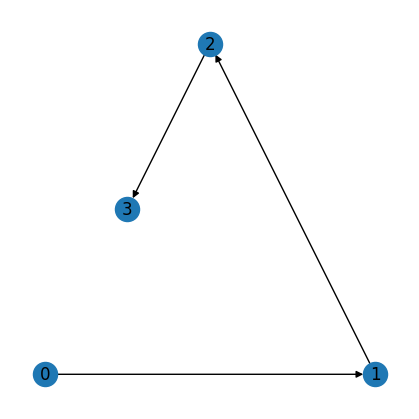

In [15]:
largest_reward_samples = topk_numpy(log_scores, k=100)

adjacency_matrices = np.unique(graphs[largest_reward_samples], axis=0)

for i in range(len(adjacency_matrices)):
    g = nx.from_numpy_array(adjacency_matrices[i], create_using=nx.MultiDiGraph)
    layout = nx.planar_layout(g)
    plt.figure(figsize=(4, 4))
    nx.draw(g, pos=layout, with_labels=True)
    plt.show()